# Tittel på prosjektet

## Beskrivelse
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

- Melissa Visnjic
- Fredrik Strande Bruun

## 1. Oppsett og innlasting av data

In [1]:
import json          # lese JSON-filene
import re            # regulære uttrykk: søk i tekst og rensing
import random        # tilfeldig trekning av dev-kontrakter (med fast seed)
import hashlib       # lager unik nøkkel til cache av LLM-kall
from pathlib import Path          # håndtere filstier
from collections import Counter   # telle ting (brukes i token-F1)
 
import pandas as pd              # tabeller
import numpy as np               # tall og logaritmiske akser
import matplotlib.pyplot as plt  # grafer

DATA_DIR = Path("data")                  # legg de tre JSON-filene her
OUT_DIR  = DATA_DIR / "processed"; OUT_DIR.mkdir(parents=True, exist_ok=True)


# dele opp i test, trening data
FULL_FILE  = DATA_DIR / "CUADv1.json"
TEST_FILE  = DATA_DIR / "test.json"
TRAIN_FILE = DATA_DIR / "train_separate_questions.json"


CATEGORIES = {
    "Expiration Date":                    "Expiration Date",
    "Renewal Term":                       "Renewal Term",
    "Notice Period To Terminate Renewal": "Notice to Terminate Renewal",
    "Cap On Liability":                   "Cap on Liability",
    "Ip Ownership Assignment":            "IP Ownership Assignment",
    "Post-Termination Services":          "Post-Termination Services",
}
CATS = list(CATEGORIES)
 
SEED = 42          # fast tilfeldighetsfrø, slik at oppdelingen blir lik hver gang
DEV_SIZE = 100     # antall kontrakter i dev-settet (trekkes fra train-delen)
 
# LLM-innstillinger. RUN_LLM = False betyr at alt unntatt LLM-kall kjøres (gratis).
RUN_LLM = True
MODEL = "gpt-6-luna"     # VALG: velg etter innledende utprøving (kvalitet/kostnad)
REASONING_EFFORT = "low"  #Starter med lav ressoneringsinnsats
#TEMPERATURE = 0            # 0 = mest mulig deterministisk svar
CHUNK_CHARS = 20000        # VALG: størrelse på tekstbiter for lange kontrakter
OVERLAP_CHARS = 2000       # VALG: overlapp mellom bitene, så en klausul ikke deles midt i
N_LLM_DEV = DEV_SIZE       # antall dev-kontrakter i første LLM-test (sjekk kostnad først!)
#N_LLM_DEV = 20
CACHE_DIR = Path("cache")  # alle LLM-svar lagres her (sparer penger og gir reproduserbarhet)

In [2]:

# Vi leter etter filene på slutten av filnavnet, slik at det ikke spiller noen rolle om
# nedlastingen har satt et tallprefiks foran (f.eks. 1792400252854_CUADv1.json).
def finn_fil(slutt):
    treff = sorted(DATA_DIR.glob(f"*{slutt}"))
    if not treff:
        raise FileNotFoundError(f"Fant ingen fil som slutter på '{slutt}' i {DATA_DIR.resolve()}")
    return treff[0]

FULL_FILE = finn_fil("CUADv1.json")                      # alle 510 kontrakter, alle annotasjoner
TEST_FILE = finn_fil("test.json")                        # offisiell test-del (102 kontrakter)
TRAIN_FILE = finn_fil("train_separate_questions.json")   # train-del (408 kontrakter)

def les_json(path):
    # CUAD-filene følger SQuAD-formatet: {"version": ..., "data": [kontrakter]}
    with open(path, encoding="utf-8") as f:
        return json.load(f)["data"]

raw_full = les_json(FULL_FILE)
test_titles = [d["title"] for d in les_json(TEST_FILE)]
train_titles = [d["title"] for d in les_json(TRAIN_FILE)]

# Fasiten henter vi kun fra CUADv1.json (alle annoterte passasjer per kategori).
# test.json og train-filen brukes bare til å vite hvilke kontrakter som hører til test og train.
print(len(raw_full), "kontrakter i CUADv1.json |", len(test_titles), "test |", len(train_titles), "train")
assert set(test_titles).isdisjoint(train_titles), "Overlapp mellom train og test!"
assert set(test_titles) | set(train_titles) == {d["title"] for d in raw_full}

510 kontrakter i CUADv1.json | 102 test | 408 train


## 2. Klargjøring av data

In [3]:

# Hver kontrakt har 41 spørsmål (én per klausultype). Hvert spørsmål har en liste "answers" med
# de annoterte passasjene. Er listen tom, finnes ikke klausulen i kontrakten ("tomt felt").
#
# Rensingen gjøres i to steg:
#   a) Behold bare de seks kategoriene vi skal bruke (dropper de øvrige 35).
#   b) Fjern tomme felter: tomme svar, svar der posisjonen (answer_start) ikke stemmer med
#      teksten, og dubletter.
#
# Resultatet blir to strukturer:
#   ann       = tabell med én rad per annotert passasje. Her finnes IKKE tomme felter.
#               Bra til utforsking, few-shot-eksempler og lengdestatistikk.
#   contracts = én post per kontrakt med fasit per kategori. Her beholdes kontraktene UTEN
#               klausul (tom liste). De trengs i evalueringen, ellers kan vi ikke måle falske
#               positive, og dermed ikke presisjon.
########################

def kategori_fra_id(qa_id):
    # id har formen "<kontrakttittel>__<kategori>"
    return qa_id.split("__")[-1]

def norm_ws(s):
    # Samler all whitespace til ett mellomrom. Brukes når tekster sammenlignes.
    return re.sub(r"\s+", " ", s.replace("\xa0", " ")).strip()

def clean_for_llm(text):
    # Forsiktig tekstrensing til språkmodellen: bare mellomrom og tomme linjer, ikke innhold.
    # Originalteksten røres ikke, fordi fasitens posisjoner peker i den.
    t = text.replace("\r\n", "\n").replace("\xa0", " ")
    t = re.sub(r"[ \t]+", " ", t)       # flere mellomrom eller tabs blir ett
    t = re.sub(r" ?\n ?", "\n", t)      # fjern mellomrom rundt linjeskift
    t = re.sub(r"\n{3,}", "\n\n", t)    # maks én tom linje
    return t.strip()

def in_text(passage, text):
    # Står utdraget ordrett i teksten (bortsett fra whitespace)? Avslører hallusinerte utdrag.
    return norm_ws(passage) in norm_ws(text)

rows = []                                  # rader til ann-tabellen
contracts = []                             # én post per kontrakt
n_uten_svar = n_tom = n_feil_pos = n_dubl = 0

for doc in raw_full:
    tekst = doc["paragraphs"][0]["context"]       # hele kontrakten ligger i ett avsnitt
    gold = {c: [] for c in CATS}
    for qa in doc["paragraphs"][0]["qas"]:
        kat = kategori_fra_id(qa["id"])
        if kat not in CATEGORIES:
            continue                              # steg a: hopp over de 35 andre kategoriene
        if not qa["answers"]:
            n_uten_svar += 1                      # tomt felt: ingen klausul i denne kontrakten
            continue
        for a in qa["answers"]:
            t, s = a["text"], a["answer_start"]
            if not t.strip():
                n_tom += 1                        # steg b: tomt svar
                continue
            if tekst[s:s + len(t)] != t:
                n_feil_pos += 1                   # steg b: posisjonen stemmer ikke med teksten
                continue
            gold[kat].append({"text": t, "start": s, "end": s + len(t)})
    for kat in CATS:
        unike = {(g["start"], g["end"]): g for g in gold[kat]}      # fjern dubletter
        n_dubl += len(gold[kat]) - len(unike)
        gold[kat] = sorted(unike.values(), key=lambda g: g["start"])
        for g in gold[kat]:
            rows.append({"title": doc["title"], "kategori": kat, **g})
    contracts.append({
        "title": doc["title"],
        "text": tekst,                            # original (brukes til posisjoner)
        "text_llm": clean_for_llm(tekst),         # renset utgave som sendes til modellen/søket
        "n_chars": len(tekst),
        "gold": gold,
        "has": {c: len(gold[c]) > 0 for c in CATS},   # fasit på kontraktsnivå: finnes klausulen?
    })

ann = pd.DataFrame(rows)
ann["n_chars"] = ann["text"].str.len()
print(f"Fjernet: {n_uten_svar} tomme felter (kontrakt/kategori uten klausul), {n_tom} tomme svar, "
      f"{n_feil_pos} med feil posisjon, {n_dubl} dubletter")
print(f"ann: {len(ann)} annoterte passasjer | contracts: {len(contracts)} kontrakter")

Fjernet: 1779 tomme felter (kontrakt/kategori uten klausul), 0 tomme svar, 0 med feil posisjon, 0 dubletter
ann: 2239 annoterte passasjer | contracts: 510 kontrakter


## 3. Utforskning av datasettet

In [4]:


# Tell hvor mange av de seks klausultypene hver kontrakt inneholder
for d in contracts:
    d["antall_klausuler"] = sum(d["has"].values())

# Lag tabell med antall kontrakter for hvert antall klausultyper
tabell = (
    pd.Series([d["antall_klausuler"] for d in contracts])
    .value_counts()
    .reindex(range(7), fill_value=0)
    .sort_index()
    .rename_axis("Antall klausultyper")
    .reset_index(name="Antall kontrakter")
)

display(tabell)

# Antall kontrakter som inneholder samtlige seks klausultyper
alle_seks = sum(d["antall_klausuler"] == 6 for d in contracts)

print(f"Antall kontrakter med alle 6 klausultypene: {alle_seks}")

,Antall klausultyper,Antall kontrakter
0,0,62
1,1,85
2,2,118
3,3,100
4,4,82
5,5,46
6,6,17


Antall kontrakter med alle 6 klausultypene: 17


In [5]:

oversikt = pd.DataFrame({
    "kategori": [CATEGORIES[c] for c in CATS],
    "kontrakter med klausul": [sum(d["has"][c] for d in contracts) for c in CATS],
    "kontrakter uten": [sum(not d["has"][c] for d in contracts) for c in CATS],
    "passasjer totalt": [int((ann["kategori"] == c).sum()) for c in CATS],
})
oversikt["andel med klausul"] = (oversikt["kontrakter med klausul"] / len(contracts)).round(2)
display(oversikt)

,kategori,kontrakter med klausul,kontrakter uten,passasjer totalt,andel med klausul
0,Expiration Date,413,97,467,0.81
1,Renewal Term,176,334,210,0.35
2,Notice to Terminate Renewal,111,399,122,0.22
3,Cap on Liability,275,235,672,0.54
4,IP Ownership Assignment,124,386,318,0.24
5,Post-Termination Services,182,328,450,0.36


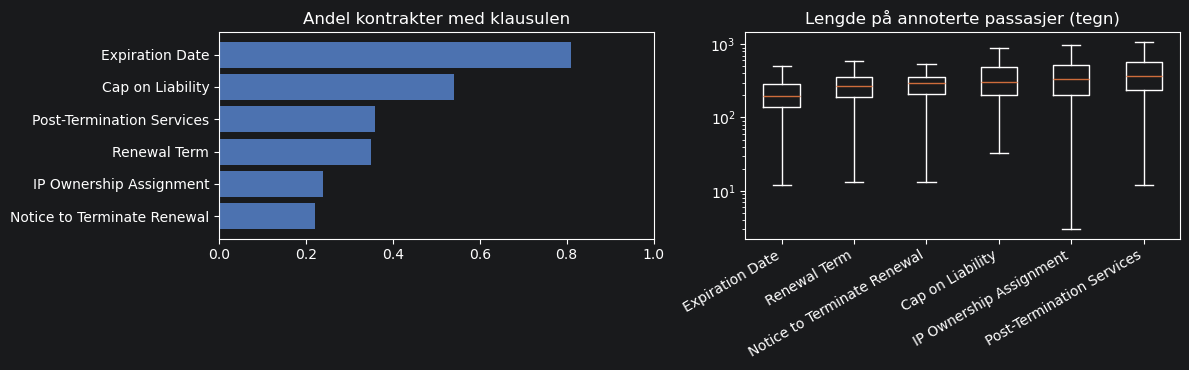

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
# Graf 1: andel kontrakter som har klausulen (viser klasseskjevhet)
o = oversikt.sort_values("andel med klausul")
ax[0].barh(o["kategori"], o["andel med klausul"], color="#4C72B0")
ax[0].set_xlim(0, 1); ax[0].set_title("Andel kontrakter med klausulen")
# Graf 2: lengde på annoterte passasjer (viktig for token-F1)
ax[1].boxplot([ann.loc[ann["kategori"] == c, "n_chars"] for c in CATS], showfliers=False)
ax[1].set_xticks(range(1, len(CATS) + 1)); ax[1].set_xticklabels([CATEGORIES[c] for c in CATS], rotation=30, ha="right")
ax[1].set_yscale("log"); ax[1].set_title("Lengde på annoterte passasjer (tegn)")
plt.tight_layout(); plt.show()

## 4. Oppdeling i utviklingssett og testsett

In [7]:

# Test = CUADs offisielle test-del. Den røres ikke før metodene er ferdig tilpasset.
# Dev  = tilfeldig utvalg fra train-delen. Her utvikler vi søkeregler og prompt.
# Reserve = resten av train (f.eks. til few-shot-eksempler).
# Delingen skjer per kontrakt, så tekst fra samme kontrakt aldri havner i både dev og test.
shuffled = sorted(train_titles)
random.Random(SEED).shuffle(shuffled)
dev_titles = set(shuffled[:DEV_SIZE])

for d in contracts:
    d["split"] = "test" if d["title"] in set(test_titles) else ("dev" if d["title"] in dev_titles else "reserve")

dev = [d for d in contracts if d["split"] == "dev"]
test = [d for d in contracts if d["split"] == "test"]
print(len(dev), "dev |", len(test), "test |", len(contracts) - len(dev) - len(test), "reserve")

antall = pd.DataFrame({
    "dev": [sum(d["has"][c] for d in dev) for c in CATS],
    "test": [sum(d["has"][c] for d in test) for c in CATS],
}, index=[CATEGORIES[c] for c in CATS])
display(antall)    # antall kontrakter MED klausul i hver delmengde

100 dev | 102 test | 308 reserve


,dev,test
Expiration Date,82,78
Renewal Term,42,26
Notice to Terminate Renewal,27,16
Cap on Liability,59,44
IP Ownership Assignment,25,23
Post-Termination Services,44,29


## 5. Søkbasert referansemetode

In [8]:

# Idé: del kontrakten i avsnitt, gi hvert avsnitt poeng etter hvor mange nøkkeluttrykk som
# treffer, og returner de beste avsnittene hvis poengsummen er høy nok.
# Finnes ingen treff, svarer metoden "ingen klausul".
# Uttrykkene under er bare et STARTPUNKT: tilpass dem på dev-data (aldri på test).
PATTERNS = {
    "Expiration Date": [r"expire[sd]?", r"expiration", r"shall terminate on", r"initial term", r"continue in (full )?force"],
    "Renewal Term": [r"renew", r"automatically extend", r"successive (one|two|\d+)[- ]year", r"additional term"],
    "Notice Period To Terminate Renewal": [r"non-?renew", r"notice of (non-?renewal|termination)", r"prior written notice", r"not (to )?renew"],
    "Cap On Liability": [r"in no event shall .{0,80}liab", r"aggregate liability", r"shall not exceed", r"limitation of liability"],
    "Ip Ownership Assignment": [r"hereby assigns?", r"work made for hire", r"all right, title,? and interest", r"exclusive property"],
    "Post-Termination Services": [r"upon (termination|expiration)", r"following (termination|expiration)", r"transition services", r"wind[- ]down"],
}
COMPILED = {c: [re.compile(p, re.I) for p in ps] for c, ps in PATTERNS.items()}

def split_passages(text, min_len=40):
    # Del opp i avsnitt (tom linje mellom). Svært lange avsnitt deles videre på linjeskift.
    out = []
    for p in (x.strip() for x in re.split(r"\n\s*\n", text)):
        out.extend(p.split("\n") if len(p) > 3000 else [p])
    return [p.strip() for p in out if len(p.strip()) >= min_len]

MIN_SCORE, TOP_K = 1, 2     # VALG: terskel og maks antall utdrag. Tune på dev.

def keyword_predict(contract, cat):
    scored = []
    for p in split_passages(contract["text_llm"]):
        score = sum(1 for rx in COMPILED[cat] if rx.search(p))   # antall nøkkeluttrykk som treffer
        if score >= MIN_SCORE:
            scored.append((score, p))
    scored.sort(key=lambda x: -x[0])
    return [p for _, p in scored[:TOP_K]]       # tom liste = "fant ingen klausul"

## 6. LLM-basert metode

In [9]:
from getpass import getpass

client = None

if RUN_LLM:
    from openai import OpenAI

    # Skjult innskriving: nøkkelen skrives ikke inn i selve koden.
    api_key = getpass("Lim inn OpenAI API-nøkkelen din: ").strip()

    if not api_key:
        raise ValueError("Du må skrive inn en API-nøkkel.")

    try:
        client = OpenAI(api_key=api_key)
    finally:
        del api_key  # Fjern den midlertidige variabelen.

    # Her lagres modellens svar, ikke API-nøkkelen.
    CACHE_DIR.mkdir(exist_ok=True)

In [10]:

# Kontrakten deles i overlappende biter. Modellen får én bit og én klausultype om gangen og
# svarer med JSON: {"found": true/false, "passages": ["ordrett utdrag", ...]}.
# Utdragene fra alle bitene samles på kontraktsnivå. Alle kall caches på disk.
# Versjon 2: kategoribeskrivelser fra category_descriptions.csv.
PROMPT_VERSION = "v3_expiration_clarified_n100"

DESCRIPTIONS = {
    "Expiration Date": (
    "Identify the passage specifying when the agreement's initial term "
    "expires or how long it lasts. This may be an explicit calendar date, "
    "a duration measured from the effective or commencement date, "
    "or a statement that the agreement continues indefinitely, perpetually, "
    "or until terminated by notice. "
    "A calendar date is not required: a stated initial-term duration "
    "is sufficient. Return the original passage, not a calculated date. "
    "Exclude durations that apply only to individual obligations, "
    "such as confidentiality or payment, rather than to the agreement itself."
),

    "Renewal Term": (
        "What is the renewal term after the initial term expires? "
        "This includes automatic extensions and unilateral extensions "
        "with prior notice."
    ),

    "Notice Period To Terminate Renewal": (
        "What is the notice period required to terminate renewal?"
    ),

    "Cap On Liability": (
        "Does the contract include a cap on liability upon the breach "
        "of a party’s obligation? This includes time limitation for "
        "the counterparty to bring claims or maximum amount for recovery."
    ),

    "Ip Ownership Assignment": (
        "Does intellectual property created by one party become the "
        "property of the counterparty, either per the terms of the "
        "contract or upon the occurrence of certain events?"
    ),

    "Post-Termination Services": (
        "Is a party subject to obligations after the termination or "
        "expiration of a contract, including any post-termination "
        "transition, payment, transfer of IP, wind-down, last-buy, "
        "or similar commitments?"
    ),
}

assert set(DESCRIPTIONS) == set(CATS)

SYSTEM_PROMPT = (
    "You are a careful contract-analysis assistant. You are given part of a commercial contract and a clause type. "
    "Decide whether this text contains a clause of that type. If so, return the relevant passages copied VERBATIM "
    "from the text (do not paraphrase; keep each passage as short as possible while covering the provision). "
    "If there is no such clause, say so. Respond ONLY with JSON: "
    '{"found": true/false, "passages": ["..."]}'
)

In [50]:
# Endelig valg av prompt per kategori.
FINAL_SYSTEM_PROMPTS = {
    cat: fs_system_prompts.get(cat, fs_system_original)
    for cat in CATS
}

PROMPT_VERSION = "v4_fewshot_selected"
VALIDATION_VERSION = "page_markers_v2"

In [51]:
def make_chunks(text, size=CHUNK_CHARS, overlap=OVERLAP_CHARS):
    # Korte kontrakter sendes hele. Lange deles i biter på 'size' tegn med 'overlap' tegn overlapp.
    if len(text) <= size:
        return [text]
    chunks, i = [], 0
    while True:
        chunks.append(text[i:i + size])
        if i + size >= len(text):
            return chunks
        i += size - overlap

#client = None
#if RUN_LLM:
#    from openai import OpenAI            # pip install openai
#    client = OpenAI()                    # leser OPENAI_API_KEY fra miljøet (aldri hardkod nøkkelen)
#   CACHE_DIR.mkdir(exist_ok=True)



def llm_call(chunk, cat):
    user = (
        f"Clause type: {cat}\n"
        f"Definition: {DESCRIPTIONS[cat]}\n\n"
        f"Contract text:\n<<<\n{chunk}\n>>>"
    )

    # Alle innstillinger som påvirker svaret, inngår i cache-nøkkelen.
    request = {
        "model": MODEL,
        "reasoning_effort": REASONING_EFFORT,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": FINAL_SYSTEM_PROMPTS[cat]},
            {"role": "user", "content": user},
        ],
    }

    key = hashlib.sha256(
        json.dumps(
            request, sort_keys=True, ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    CACHE_DIR.mkdir(exist_ok=True)
    cache_file = CACHE_DIR / f"{key}.json"

    # Gjenbruk svar når nøyaktig samme forespørsel er kjørt før.
    if cache_file.exists():
        with open(cache_file, encoding="utf-8") as f:
            return json.load(f)

    if client is None:
        raise RuntimeError(
            "Kjør cellen for API-nøkkelen med RUN_LLM = True først."
        )

    resp = client.chat.completions.create(**request)
    choice = resp.choices[0]

    # Tekniske problemer skal ikke registreres som «ingen klausul».
    if choice.finish_reason != "stop" or not choice.message.content:
        raise RuntimeError(
            f"Modellen ga ikke et fullstendig svar. "
            f"finish_reason={choice.finish_reason}"
        )

    raw = choice.message.content
    parsed = json.loads(raw)

    # Kontroller svarformatet før resultatet lagres.
    if (
        not isinstance(parsed, dict)
        or not isinstance(parsed.get("found"), bool)
        or not isinstance(parsed.get("passages"), list)
        or not all(isinstance(p, str) for p in parsed["passages"])
    ):
        raise ValueError("Modellsvaret har feil JSON-struktur.")

    out = {
        "model": resp.model,
        "reasoning_effort": REASONING_EFFORT,
        "raw": raw,
        "usage": resp.usage.model_dump() if resp.usage else None,
    }

    with open(cache_file, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)

    return out

def passage_in_contract(passage, document):
    """Kontroller sitatet, med toleranse for utelatte sidemarkører."""

    if in_text(passage, document["text_llm"]):
        return True

    # Fjern bare sidemarkører som står alene på en linje:
    # «Page 23» eller «- 6 -».
    text_without_page_markers = re.sub(
        r"^[ \t]*(?:Page[ \t]+\d+|-[ \t]*\d+[ \t]*-)[ \t]*\r?$",
        "",
        document["text"],
        flags=re.MULTILINE,
    )

    return in_text(passage, text_without_page_markers)


def llm_predict(contract, cat):
    text = contract["text_llm"]
    funnet = []

    for ch in make_chunks(text):
        try:
            d = json.loads(llm_call(ch, cat)["raw"])
        except json.JSONDecodeError as exc:
            # Stopp ved ugyldig JSON, så feilen ikke blir et negativt treff.
            raise ValueError(
                f"Ugyldig JSON for {contract['title']} / {cat}"
            ) from exc

        if d.get("found"):
            funnet += [
                p for p in d.get("passages", [])
                if isinstance(p, str) and p.strip()
            ]

    # Fjern dubletter og kontroller at utdragene finnes i kontrakten.
    # Kontrollen tillater at sidemarkører på egne linjer er utelatt.
    seen, final = set(), []

    for p in funnet:
        if p not in seen and passage_in_contract(p, contract):
            seen.add(p)
            final.append(p)

    return final

## 7. Evalueringsmål

In [12]:

# To nivåer:
#  (a) Kontraktsnivå: er det funnet en klausul i kontrakter som har en? Presisjon, recall, F1.
#      Positiv i fasit = kontrakten har minst én annotert passasje.
#      Positiv fra metoden = metoden returnerer minst ett utdrag.
#  (b) Passasjenivå: hvor godt treffer utdraget riktig tekst? Token-F1 (overlapp i ord).
#      Vi matcher begge veier: hver fasitpassasje mot beste utdrag (recall-side),
#      og hvert utdrag mot beste fasitpassasje (presisjons-side).
def tokens(s):
    return re.findall(r"\w+", s.lower())

def token_f1(a, b):
    ta, tb = tokens(a), tokens(b)
    if not ta or not tb:
        return 0.0
    felles = sum((Counter(ta) & Counter(tb)).values())
    if felles == 0:
        return 0.0
    p, r = felles / len(ta), felles / len(tb)
    return 2 * p * r / (p + r)

def span_scores(pred, gold):
    rec = sum(max(token_f1(p, g) for p in pred) for g in gold) / len(gold)
    prec = sum(max(token_f1(p, g) for g in gold) for p in pred) / len(pred)
    return rec, prec

def evaluate(predict_fn, data, cats, name):
    rows, details = [], []
    for cat in cats:
        tp = fp = fn = tn = 0
        recs, precs = [], []
        for k in data:
            gold = [g["text"] for g in k["gold"][cat]]
            pred = predict_fn(k, cat)
            details.append({"title": k["title"], "kategori": cat, "gold": gold, "pred": pred})
            if gold and pred:
                tp += 1
                r, p = span_scores(pred, gold); recs.append(r); precs.append(p)
            elif gold:
                fn += 1                       # klausul finnes, men metoden fant ingenting
            elif pred:
                fp += 1                       # ingen klausul, men metoden fant noe
            else:
                tn += 1
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        rows.append({"metode": name, "kategori": CATEGORIES[cat], "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                     "presisjon": P, "recall": R, "F1": F,
                     "span_recall": np.mean(recs) if recs else np.nan,
                     "span_presisjon": np.mean(precs) if precs else np.nan})
    return pd.DataFrame(rows), details

In [13]:
EVAL_VERSION = "eval_v2"


def evaluate_saved(details, cats, name):
    """
    Evaluerer lagrede prediksjoner.

    Kontraktsnivå:
        Presisjon, recall og F1 for forekomst av klausultypen.

    Passasjenivå:
        Dekning av fasit: beste token-F1 for hver fasitpassasje.
        Treffsikkerhet for utdrag: beste token-F1 for hvert utdrag.

    Manglende treff gir null. Gjennomsnittene beregnes over
    henholdsvis alle fasitpassasjer og alle returnerte utdrag.
    """
    rows = []

    for cat in cats:
        category_details = [
            d for d in details if d["kategori"] == cat
        ]

        if not category_details:
            raise ValueError(f"Mangler resultater for {cat}.")

        titles = [d["title"] for d in category_details]
        if len(titles) != len(set(titles)):
            raise ValueError(f"Dupliserte kontraktresultater for {cat}.")

        tp = fp = fn = tn = 0
        gold_scores = []
        pred_scores = []

        for d in category_details:
            gold = d["gold"]
            pred = d["pred"]

            # Forekomst av klausultypen på kontraktsnivå.
            if gold and pred:
                tp += 1
            elif pred:
                fp += 1
            elif gold:
                fn += 1
            else:
                tn += 1

            # Hver fasitpassasje får en skår.
            # Ingen prediksjon betyr null.
            for g in gold:
                best_match = max(
                    (token_f1(p, g) for p in pred),
                    default=0.0,
                )
                gold_scores.append(best_match)

            # Hvert returnert utdrag får en skår.
            # Ingen fasit betyr null.
            for p in pred:
                best_match = max(
                    (token_f1(p, g) for g in gold),
                    default=0.0,
                )
                pred_scores.append(best_match)

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        rows.append({
            "metode": name,
            "kategori": CATEGORIES[cat],
            "antall_kontrakter": len(category_details),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "presisjon": precision,
            "recall": recall,
            "F1": f1,
            "antall_fasitpassasjer": len(gold_scores),
            "antall_utdrag": len(pred_scores),
            "dekning_fasit": (
                float(np.mean(gold_scores))
                if gold_scores else np.nan
            ),
            "treffsikkerhet_utdrag": (
                float(np.mean(pred_scores))
                if pred_scores else np.nan
            ),
        })

    return pd.DataFrame(rows)

## 8. Foreløpige resultater på utviklingssettet

In [32]:
# Begge metodene bruker de samme kontraktene i sammenligningen.
eval_dev = dev[:N_LLM_DEV] if RUN_LLM else dev
print(f"Evaluerer på {len(eval_dev)} utviklingskontrakter.")

# Søkebasert referansemetode
res_kw, det_kw = evaluate(keyword_predict, eval_dev, CATS, "søk")
display(res_kw.round(3))
print("Makro-F1, søk:", round(res_kw["F1"].mean(), 3))

Evaluerer på 100 utviklingskontrakter.


,metode,kategori,TP,FP,FN,TN,presisjon,recall,F1,span_recall,span_presisjon
0,søk,Expiration Date,68,9,14,9,0.883,0.829,0.855,0.349,0.283
1,søk,Renewal Term,37,23,5,35,0.617,0.881,0.725,0.396,0.364
2,søk,Notice to Terminate Renewal,23,27,4,46,0.460,0.852,0.597,0.441,0.347
3,søk,Cap on Liability,43,5,16,36,0.896,0.729,0.804,0.317,0.347
4,søk,IP Ownership Assignment,21,18,4,57,0.538,0.840,0.656,0.323,0.353
5,søk,Post-Termination Services,32,21,12,35,0.604,0.727,0.660,0.332,0.359


Makro-F1, søk: 0.716


In [33]:
# LLM på en liten del av utviklingssettet
results = [res_kw]
det_llm = []

# LLM-basert metode
if RUN_LLM:
    res_llm, det_llm = evaluate(llm_predict, eval_dev, CATS, "LLM")
    display(res_llm.round(3))
    print("Makro-F1, LLM:", round(res_llm["F1"].mean(), 3))
    results.append(res_llm)

,metode,kategori,TP,FP,FN,TN,presisjon,recall,F1,span_recall,span_presisjon
0,LLM,Expiration Date,78,6,4,12,0.929,0.951,0.940,0.836,0.810
1,LLM,Renewal Term,40,10,2,48,0.800,0.952,0.870,0.878,0.881
2,LLM,Notice to Terminate Renewal,24,12,3,61,0.667,0.889,0.762,0.888,0.880
3,LLM,Cap on Liability,52,4,7,37,0.929,0.881,0.904,0.712,0.778
4,LLM,IP Ownership Assignment,24,18,1,57,0.571,0.960,0.716,0.701,0.686
5,LLM,Post-Termination Services,44,41,0,15,0.518,1.000,0.682,0.725,0.427


Makro-F1, LLM: 0.812


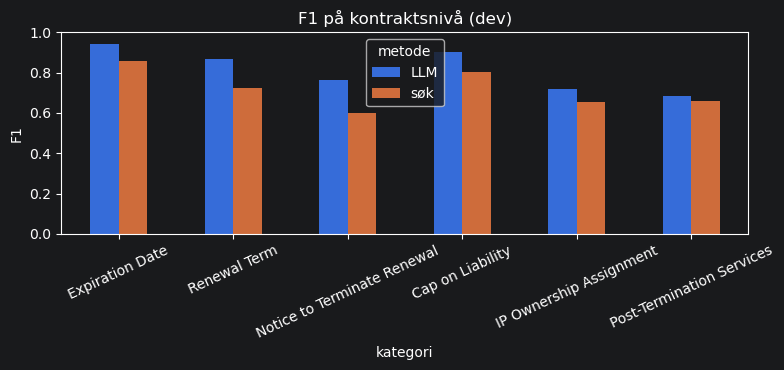

In [34]:
# Graf: F1 per kategori for metodene som er kjørt
alle = pd.concat(results)

piv = alle.pivot(
    index="kategori",
    columns="metode",
    values="F1"
).reindex([CATEGORIES[c] for c in CATS])

piv.plot.bar(
    figsize=(8, 3.8),
    rot=25,
    ylim=(0, 1),
    title="F1 på kontraktsnivå (dev)"
)

plt.ylabel("F1")
plt.tight_layout()
plt.show()

In [35]:
# Kontroller at begge metodene har resultater for samme utvalg.
expected = {
    (d["title"], cat)
    for d in eval_dev
    for cat in CATS
}

for name, details in [("søk", det_kw), ("LLM", det_llm)]:
    actual = {
        (d["title"], d["kategori"])
        for d in details
    }

    if actual != expected or len(details) != len(expected):
        raise ValueError(
            f"{name}: Resultatene dekker ikke nøyaktig "
            "det nåværende evalueringsutvalget."
        )

# Beregn nye mål fra eksisterende prediksjoner.
res_kw_eval2 = evaluate_saved(det_kw, CATS, "søk")
res_llm_eval2 = evaluate_saved(det_llm, CATS, "LLM")

results_eval2 = pd.concat(
    [res_kw_eval2, res_llm_eval2],
    ignore_index=True,
)

columns = [
    "metode",
    "kategori",
    "presisjon",
    "recall",
    "F1",
    "dekning_fasit",
    "treffsikkerhet_utdrag",
    "antall_fasitpassasjer",
    "antall_utdrag",
]

display(results_eval2[columns].round(3))

print("Antall utviklingskontrakter:", len(eval_dev))
print("Makro-F1, søk:", round(res_kw_eval2["F1"].mean(), 3))
print("Makro-F1, LLM:", round(res_llm_eval2["F1"].mean(), 3))

,metode,kategori,presisjon,recall,F1,dekning_fasit,treffsikkerhet_utdrag,antall_fasitpassasjer,antall_utdrag
0,søk,Expiration Date,0.883,0.829,0.855,0.287,0.249,96,137
1,søk,Renewal Term,0.617,0.881,0.725,0.324,0.217,49,83
2,søk,Notice to Terminate Renewal,0.460,0.852,0.597,0.356,0.155,29,82
3,søk,Cap on Liability,0.896,0.729,0.804,0.228,0.331,129,66
4,søk,IP Ownership Assignment,0.538,0.840,0.656,0.269,0.227,63,53
5,søk,Post-Termination Services,0.604,0.727,0.660,0.269,0.240,95,82
6,LLM,Expiration Date,0.929,0.951,0.940,0.750,0.718,96,103
7,LLM,Renewal Term,0.800,0.952,0.870,0.756,0.679,49,55
8,LLM,Notice to Terminate Renewal,0.667,0.889,0.762,0.735,0.562,29,39
9,LLM,Cap on Liability,0.929,0.881,0.904,0.625,0.694,129,107


Antall utviklingskontrakter: 100
Makro-F1, søk: 0.716
Makro-F1, LLM: 0.812


## 9. Feilanalyse

In [18]:

# Se på konkrete feil: falske negative (FN) og falske positive (FP). Noter eksempler til rapporten
# (feil klausul, utdrag som bare delvis dekker bestemmelsen, tilsynelatende oppdiktede utdrag osv.).
def vis_feil(details, type_="FN", n=3, bredde=300):
    vist = 0
    for d in details:
        fn_ = d["gold"] and not d["pred"]
        fp_ = d["pred"] and not d["gold"]
        if (type_ == "FN" and fn_) or (type_ == "FP" and fp_):
            print(f"--- {CATEGORIES[d['kategori']]} | {d['title'][:60]}")
            print("FASIT:", [norm_ws(g)[:bredde] for g in d["gold"][:2]])
            print("METODE:", [norm_ws(p)[:bredde] for p in d["pred"][:2]])
            vist += 1
            if vist >= n:
                break

print("=== Baseline: falske negative ==="); vis_feil(det_kw, "FN")
print("=== Baseline: falske positive ==="); vis_feil(det_kw, "FP")

=== Baseline: falske negative ===
--- Expiration Date | DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPONSORSHIP AGREE
FASIT: ['This Agreement shall become effective as of the day and year first above written and shall govern the relations between the parties hereto thereafter, unless terminated as set forth in this Section 6.']
METODE: []
--- Expiration Date | GLOBALTECHNOLOGIESLTD_06_08_2020-EX-10.16-CONSULTING AGREEME
FASIT: ['This Agreement shall be in full force and effect commencing on January 2, 2020 and shall remain in effect for one (1) year or until Consultant completes the services requested']
METODE: []
--- Expiration Date | AzulSa_20170303_F-1A_EX-10.3_9943903_EX-10.3_Maintenance Agr
FASIT: ['This Amendment shall enter into force on the date of its signature by both Parties and, unless otherwise agreed upon in writing by the Parties through a subsequent amendment to the GMA, shall remain in force for the term of the referenced GMA.']
METODE: []
=== Baseline: falske positive 

In [19]:
# Undersøk falske positive i kategoriene med lavest presisjon.
for cat in ["Ip Ownership Assignment", "Post-Termination Services"]:
    print(f"\n=== {CATEGORIES[cat]}: falske positive ===")

    kategori_feil = [
        d for d in det_llm
        if d["kategori"] == cat
    ]

    vis_feil(kategori_feil, "FP", n=3, bredde=1500)

# Se også på klausuler LLM-metoden overser.
print("\n=== LLM: falske negative ===")
vis_feil(det_llm, "FN", n=5, bredde=1500)


=== IP Ownership Assignment: falske positive ===
--- IP Ownership Assignment | BORROWMONEYCOM,INC_06_11_2020-EX-10.1-JOINT VENTURE AGREEMEN
FASIT: []
METODE: ['Where allowed by statute, title to all Venture property, including intellectual property, will remain in the name of the Venture. Where joint ventures are not recognized by statute as separate legal entities, Venture property, including intellectual property, will be held in the name of one or more Members.']
--- IP Ownership Assignment | SENMIAOTECHNOLOGYLTD_02_19_2019-EX-10.5-Collaboration Agreem
FASIT: []
METODE: ['Party A has exclusive rights and interests in all rights, ownership, titles, interests and intellectual property rights arising from or created by the performance of this Agreement.']
--- IP Ownership Assignment | ACCURAYINC_09_01_2010-EX-10.31-DISTRIBUTOR AGREEMENT
FASIT: []
METODE: ['Accuray will be registered as the sole owner of any rights, title and interest to any of the Products or Spare Parts, as the case 

In [20]:
from itertools import combinations

category = "Post-Termination Services"

post_details = [
    d for d in det_llm
    if d["kategori"] == category
]

overview_rows = []
suspected_pairs = []

for d in post_details:
    predictions = d["pred"]
    gold = d["gold"]
    flagged_indices = set()
    pair_count = 0

    # Sammenlign bare utdrag fra samme kontrakt.
    for i, j in combinations(range(len(predictions)), 2):
        a = norm_ws(predictions[i])
        b = norm_ws(predictions[j])

        if not a or not b:
            continue

        similarity = token_f1(a, b)

        if a == b:
            reason = "Like etter normalisering av mellomrom"
        elif a in b or b in a:
            reason = "Ett utdrag finnes i sin helhet i det andre"
        elif similarity >= 0.80:
            reason = "Høy ordlikhet – må vurderes manuelt"
        else:
            continue

        pair_count += 1
        flagged_indices.update([i, j])

        suspected_pairs.append({
            "title": d["title"],
            "utdrag_a": i + 1,
            "utdrag_b": j + 1,
            "grunn": reason,
            "token_F1": similarity,
            "tekst_a": predictions[i],
            "tekst_b": predictions[j],
        })

    overview_rows.append({
        "kontrakt": d["title"],
        "fasitpassasjer": len(gold),
        "utdrag": len(predictions),
        "utdrag_uten_fasit": len(predictions) if not gold else 0,
        "mulige_gjentakelsespar": pair_count,
        "utdrag_i_flaggede_par": len(flagged_indices),
    })

overview = pd.DataFrame(overview_rows).sort_values(
    ["utdrag", "mulige_gjentakelsespar"],
    ascending=False,
)

display(overview)

print("Antall kontrakter:", len(post_details))
print("Fasitpassasjer totalt:", overview["fasitpassasjer"].sum())
print("Utdrag totalt:", overview["utdrag"].sum())
print(
    "Utdrag i kontrakter uten annotert klausul:",
    overview["utdrag_uten_fasit"].sum(),
)
print("Antall flaggede par:", len(suspected_pairs))
print(
    "Antall utdrag som inngår i minst ett flagget par:",
    overview["utdrag_i_flaggede_par"].sum(),
)

# Vis opptil fem par for manuell vurdering.
for pair in sorted(
    suspected_pairs,
    key=lambda x: x["token_F1"],
    reverse=True,
)[:5]:
    print("\n" + "=" * 70)
    print("KONTRAKT:", pair["title"])
    print("GRUNN:", pair["grunn"])
    print("TOKEN-F1:", round(pair["token_F1"], 3))
    print(f"\nUTDRAG {pair['utdrag_a']}:\n{pair['tekst_a']}")
    print(f"\nUTDRAG {pair['utdrag_b']}:\n{pair['tekst_b']}")

if not suspected_pairs:
    print("\nIngen par ble flagget med disse kriteriene.")

,kontrakt,fasitpassasjer,utdrag,utdrag_uten_fasit,mulige_gjentakelsespar,utdrag_i_flaggede_par
32,PapaJohnsInternationalInc_20190617_8-K_EX-10.1...,2,16,0,1,2
61,"IPAYMENT,INC_05_14_2007-EX-10.1-SPONSORSHIP AG...",0,14,14,3,3
77,"BERKELEYLIGHTS,INC_06_26_2020-EX-10.12-COLLABO...",4,13,0,1,2
67,OFGBANCORP_03_28_2007-EX-10.23-OUTSOURCING AGR...,2,13,0,0,0
42,FuelcellEnergyInc_20191106_8-K_EX-10.1_1186800...,1,12,0,0,0
...,...,...,...,...,...,...
51,FEDERATEDGOVERNMENTINCOMESECURITIESINC_04_28_2...,0,0,0,0,0
58,"SOLUTIONSVENDINGINTERNATIONAL,INC_03_31_2020-E...",0,0,0,0,0
90,PcquoteComInc_19990721_S-1A_EX-10.11_6377149_E...,0,0,0,0,0
91,BellringBrandsInc_20190920_S-1_EX-10.12_118170...,0,0,0,0,0


Antall kontrakter: 100
Fasitpassasjer totalt: 95
Utdrag totalt: 437
Utdrag i kontrakter uten annotert klausul: 133
Antall flaggede par: 13
Antall utdrag som inngår i minst ett flagget par: 23

KONTRAKT: ENTERTAINMENTGAMINGASIAINC_02_15_2005-EX-10.5-DISTRIBUTOR AGREEMENT
GRUNN: Høy ordlikhet – må vurderes manuelt
TOKEN-F1: 0.967

UTDRAG 7:
for a period beginning from the date of this Agreement and ending three (3) years after the termination of this Agreement, neither Distributor nor any of its affiliates or representatives will: (1) employ or solicit to employ any of the employees of Vendor; or (2) encourage of the employees of the Vendor or its subsidiaries to leave the employment of Vendor

UTDRAG 8:
for a period beginning from the date of this Agreement and ending three (3) years after the termination of this Agreement, neither Vendor nor any of its affiliates or representatives will: (1) employ or solicit to employ any of the employees of Distributor; or (2) encourage of the employ

## 10. Lagring av resultater og oppsett

In [21]:
# Samle resultatene fra den siste evalueringen.
alle = pd.concat(results, ignore_index=True)

alle.to_csv(
    OUT_DIR / f"{PROMPT_VERSION}_resultater_dev.csv",
    index=False,
)

config = {
    "prompt_version": PROMPT_VERSION,
    "description_source": "category_descriptions.csv",
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "chunk_chars": CHUNK_CHARS,
    "overlap_chars": OVERLAP_CHARS,
    "seed": SEED,
    "dev_size": DEV_SIZE,
    "n_llm_dev": N_LLM_DEV,
    "eval_titles": [d["title"] for d in eval_dev],
    "min_score": MIN_SCORE,
    "top_k": TOP_K,
    "system_prompt": SYSTEM_PROMPT,
    "descriptions": DESCRIPTIONS,
    "kategorier": CATS,
}

with open(
    OUT_DIR / f"{PROMPT_VERSION}_run_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

with open(
    OUT_DIR / f"{PROMPT_VERSION}_prediksjoner_dev.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {"søk": det_kw, "LLM": det_llm},
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"{PROMPT_VERSION} lagret i {OUT_DIR.resolve()}")

v3_expiration_clarified_n100 lagret i C:\Users\fredr\Documents\GitHub\llmProject\data\processed


In [22]:
# Les inn prediksjonene fra versjon 1.
with open(OUT_DIR / "v1_prediksjoner_dev.json", encoding="utf-8") as f:
    saved_v1 = json.load(f)

v1_lookup = {
    (d["title"], d["kategori"]): d["pred"]
    for d in saved_v1["LLM"]
}

# Kontroller at v1 har resultater for hele det nåværende utvalget.
missing = [
    (d["title"], cat)
    for d in eval_dev
    for cat in CATS
    if (d["title"], cat) not in v1_lookup
]

if missing:
    raise ValueError(
        f"Mangler {len(missing)} kontrakt/kategori-resultater fra v1."
    )

def predict_saved_v1(contract, cat):
    return v1_lookup[(contract["title"], cat)]

# Beregn v1-resultater på nøyaktig samme kontrakter som v2.
res_v1_same, _ = evaluate(
    predict_saved_v1, eval_dev, CATS, "LLM v1"
)

comparison = (
    res_v1_same.set_index("kategori")[["presisjon", "recall", "F1"]]
    .add_suffix("_v1")
    .join(
        res_llm.set_index("kategori")[["presisjon", "recall", "F1"]]
        .add_suffix("_v2")
    )
)

comparison["endring_F1"] = comparison["F1_v2"] - comparison["F1_v1"]

display(comparison.round(3))
print("Antall kontrakter:", len(eval_dev))
print("Makro-F1 v1:", round(comparison["F1_v1"].mean(), 3))
print("Makro-F1 v2:", round(comparison["F1_v2"].mean(), 3))

,presisjon_v1,recall_v1,F1_v1,presisjon_v2,recall_v2,F1_v2,endring_F1
kategori,,,,,,,
Expiration Date,0.937,0.902,0.919,0.928,0.939,0.933,0.014
Renewal Term,0.804,0.976,0.882,0.800,0.952,0.870,-0.012
Notice to Terminate Renewal,0.619,0.963,0.754,0.667,0.889,0.762,0.008
Cap on Liability,0.885,0.915,0.900,0.927,0.864,0.895,-0.005
IP Ownership Assignment,0.444,0.960,0.608,0.571,0.960,0.716,0.109
Post-Termination Services,0.530,1.000,0.693,0.518,1.000,0.682,-0.011


Antall kontrakter: 100
Makro-F1 v1: 0.793
Makro-F1 v2: 0.81


In [23]:
# Undersøk et oversett utdrag som uttrykkelig angir 18 måneders varighet.
contract = next(
    d for d in eval_dev
    if "ON2TECHNOLOGIES" in d["title"]
)
cat = "Expiration Date"

print("Kontrakt:", contract["title"])

for i, chunk in enumerate(make_chunks(contract["text_llm"]), start=1):
    # Gjenskap forespørselen slik llm_call() lager den.
    user = (
        f"Clause type: {cat}\n"
        f"Definition: {DESCRIPTIONS[cat]}\n\n"
        f"Contract text:\n<<<\n{chunk}\n>>>"
    )

    request = {
        "model": MODEL,
        "reasoning_effort": REASONING_EFFORT,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user},
        ],
    }

    key = hashlib.sha256(
        json.dumps(
            request, sort_keys=True, ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE_DIR / f"{key}.json"

    print(f"\n--- Tekstbit {i} ---")

    if not cache_file.exists():
        print("Fant ikke lagret svar for disse innstillingene.")
        continue

    with open(cache_file, encoding="utf-8") as f:
        saved = json.load(f)

    print("RÅSVAR:", saved["raw"])

    parsed = json.loads(saved["raw"])
    for passage in parsed.get("passages", []):
        print(
            "Består ordrett-kontrollen:",
            in_text(passage, contract["text_llm"])
        )

Kontrakt: ON2TECHNOLOGIES,INC_11_17_2006-EX-10.3-SUPPORT AND MAINTENANCE AGREEMENT

--- Tekstbit 1 ---
RÅSVAR: {"found": false, "passages": []}

--- Tekstbit 2 ---
RÅSVAR: {"found": true, "passages": ["Except as otherwise set forth in Sections 9.2 and 9.3 or Exhibit A hereof, the term of this Agreement shall be eighteen (18) months (\"Term\")."]}
Består ordrett-kontrollen: True

--- Tekstbit 3 ---
RÅSVAR: {"found":false,"passages":[]}


In [24]:
expiration_details = [
    d for d in det_llm
    if d["kategori"] == "Expiration Date"
]

print("=== Expiration Date: falske positive ===")
vis_feil(expiration_details, "FP", n=5, bredde=2000)

=== Expiration Date: falske positive ===
--- Expiration Date | INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEME
FASIT: []
METODE: ['The license hereby granted shall commence on the date the Franchised Restaurant opens for business (the "Commencement Date"), and, unless sooner terminated in accordance with the terms and provisions of this Agreement, shall continue for the period of years set forth on SCHEDULE 1 hereto (the "Term").']
--- Expiration Date | BravatekSolutionsInc_20170418_8-K_EX-10.1_10205739_EX-10.1_R
FASIT: []
METODE: ['Agreement Term: 1 Year', 'Unless terminated earlier as provided herein, this Agreement shall have the Term set forth above (which commences on the Effective Date).']
--- Expiration Date | HEALTHGATEDATACORP_11_24_1999-EX-10.1-HOSTING AND MANAGEMENT
FASIT: []
METODE: ['If the Licence Agreement has expired or has been lawfully terminated this Agreement will automatically terminate on the same date.']
--- Expiration Date | ALAMOGORDOFINANCIALCORP_

In [25]:
# Ta med utvalgsstørrelse og evalueringsversjon i filnavnet.
eval_prefix = (
    f"{PROMPT_VERSION}_n{len(eval_dev)}_{EVAL_VERSION}"
)

results_eval2.to_csv(
    OUT_DIR / f"{eval_prefix}_resultater_dev.csv",
    index=False,
)

evaluation_info = {
    "evaluation_version": EVAL_VERSION,
    "prompt_version": PROMPT_VERSION,
    "antall_kontrakter": len(eval_dev),
    "eval_titles": [d["title"] for d in eval_dev],
    "dekning_fasit": (
        "Gjennomsnittlig beste token-F1 per fasitpassasje. "
        "Manglende prediksjon gir null."
    ),
    "treffsikkerhet_utdrag": (
        "Gjennomsnittlig beste token-F1 per returnert utdrag. "
        "Manglende fasit gir null."
    ),
    "vekting": (
        "Hver passasje teller likt innenfor kategorien. "
        "Beste match beregnes uten krav om en-til-en-matching."
    ),
}

with open(
    OUT_DIR / f"{eval_prefix}_beskrivelse.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(evaluation_info, f, ensure_ascii=False, indent=2)

print("Ny evaluering lagret med prefiks:", eval_prefix)

Ny evaluering lagret med prefiks: v3_expiration_clarified_n100_n100_eval_v2


In [26]:
import hashlib
import json

# Finn kontrakten i utviklingsutvalget som nettopp ble evaluert.
cat = "Expiration Date"
matches = [
    d for d in eval_dev
    if d["title"].startswith("IPAYMENT,INC_05_14_2007")
]

if len(matches) != 1:
    raise ValueError(
        f"Forventet én IPAYMENT-kontrakt, men fant {len(matches)}."
    )

doc = matches[0]
text = doc["text_llm"]
chunks = list(make_chunks(text))

print("Kontrakt:", doc["title"])
print("Kategori:", cat)
print("Antall tekstbiter:", len(chunks))
print("Gjeldende definisjon:", DESCRIPTIONS[cat])

print("\n=== FASIT OG TEKSTKONTROLL ===")
for i, annotation in enumerate(doc["gold"][cat], start=1):
    passage = annotation["text"]
    matching_chunks = [
        j for j, chunk in enumerate(chunks, start=1)
        if in_text(passage, chunk)
    ]

    print(f"\nFasitpassasje {i}:")
    print(passage)
    print("Finnes i hele modellteksten:", in_text(passage, text))
    print("Finnes samlet i tekstbit(er):", matching_chunks)

print("\n=== LAGRET ENDELIG PREDIKSJON ===")
saved = [
    row for row in det_llm
    if row["title"] == doc["title"] and row["kategori"] == cat
]

if len(saved) == 1:
    print(saved[0]["pred"])
else:
    print(f"Fant {len(saved)} resultatposter; forventet én.")

print("\n=== LAGREDE RÅSVAR PER TEKSTBIT ===")
for i, chunk in enumerate(chunks, start=1):
    # Samme forespørselsoppsett som brukes til cache-nøkkelen.
    user_message = (
        f"Clause type: {cat}\n"
        f"Definition: {DESCRIPTIONS[cat]}\n\n"
        f"Contract text:\n<<<\n{chunk}\n>>>"
    )

    request = {
        "model": MODEL,
        "reasoning_effort": REASONING_EFFORT,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_message},
        ],
    }

    key = hashlib.sha256(
        json.dumps(
            request, sort_keys=True, ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE_DIR / f"{key}.json"

    print(f"\n--- Tekstbit {i} ---")

    if not cache_file.exists():
        print("Ingen cachefil funnet med dette forespørselsoppsettet.")
        print("Ingen ny API-forespørsel er sendt.")
        continue

    with open(cache_file, encoding="utf-8") as f:
        cached = json.load(f)

    raw = cached["raw"]
    print("RÅSVAR:", raw)

    try:
        parsed = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        print("FEIL: Råsvaret kan ikke leses som JSON.")
        continue

    print("found:", parsed.get("found"))

    for j, passage in enumerate(parsed.get("passages", []), start=1):
        print(f"\nReturnert passasje {j}:")
        print(passage)
        print("Ordrett i denne tekstbiten:", in_text(passage, chunk))
        print("Består ordrett-kontrollen mot hele teksten:",
              in_text(passage, text))

Kontrakt: IPAYMENT,INC_05_14_2007-EX-10.1-SPONSORSHIP AGREEMENT
Kategori: Expiration Date
Antall tekstbiter: 6
Gjeldende definisjon: Identify the passage specifying when the agreement's initial term expires or how long it lasts. This may be an explicit calendar date, a duration measured from the effective or commencement date, or a statement that the agreement continues indefinitely, perpetually, or until terminated by notice. A calendar date is not required: a stated initial-term duration is sufficient. Return the original passage, not a calculated date. Exclude durations that apply only to individual obligations, such as confidentiality or payment, rather than to the agreement itself.

=== FASIT OG TEKSTKONTROLL ===

Fasitpassasje 1:
The initial term of this Agreement shall be four (4) Processing Years commencing on the Effective Date of this Agreement and ending on June 30, 2010 unless
Finnes i hele modellteksten: True
Finnes samlet i tekstbit(er): [4]

=== LAGRET ENDELIG PREDIKSJON

In [27]:
from difflib import SequenceMatcher

# Hent det lagrede svaret for tekstbit 4 med samme cache-nøkkel.
chunk = chunks[3]

user_message = (
    f"Clause type: {cat}\n"
    f"Definition: {DESCRIPTIONS[cat]}\n\n"
    f"Contract text:\n<<<\n{chunk}\n>>>"
)

request = {
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "response_format": {"type": "json_object"},
    "messages": [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_message},
    ],
}

key = hashlib.sha256(
    json.dumps(
        request, sort_keys=True, ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

with open(CACHE_DIR / f"{key}.json", encoding="utf-8") as f:
    cached = json.load(f)

passage = json.loads(cached["raw"])["passages"][0]

# Vis originalteksten fra samme start som fasitpassasjen.
source = norm_ws(chunk)
gold = norm_ws(doc["gold"][cat][0]["text"])
start = source.find(gold)

if start == -1:
    raise ValueError("Fant ikke fasitpassasjen i tekstbit 4.")

print("=== ORIGINALTEKST MED KONTEKST ===")
print(source[max(0, start - 150):start + 1400])

print("\n=== MODELLENS UTDRAG ===")
print(passage)

# Vis hvor det sammenhengende, ordrette samsvaret først stopper.
prediction = norm_ws(passage)
source_tail = source[start:]

common_length = 0
for original_char, predicted_char in zip(source_tail, prediction):
    if original_char != predicted_char:
        break
    common_length += 1

print("\n=== FØRSTE AVVIK EFTER NORMALISERING AV MELLOMROM ===")
print("Antall like tegn fra starten:", common_length)

left = max(0, common_length - 80)
right = common_length + 250

print("Original:", repr(source_tail[left:right]))
print("Modell:  ", repr(prediction[left:right]))

=== ORIGINALTEKST MED KONTEKST ===
9. The provisions of this Section 9 shall survive the termination or expiration of this Agreement. SECTION 10 TERM AND TERMINATION 10.1 Initial Term. The initial term of this Agreement shall be four (4) Processing Years commencing on the Effective Date of this Agreement and ending on June 30, 2010 unless Page 23 terminated earlier as provided in this Section 10. Thereafter, this Agreement shall automatically continue in effect until either party gives the other at least six (6) months prior written notice of termination. 10.2 Termination by SERVICERS. SERVICERS may terminate this Agreement prior to its expiration for cause upon prior written notice to ISO as follows: (a) Upon a Material breach of any representation, warranty or covenant in this Agreement by ISO which is not cured by ISO within sixty (60) days of receipt of written notice from SERVICERS; provided however, that if ISO is attempting in good faith to cure such breach within said sixty (60

In [28]:
# Undersøk formateringen i originalteksten, før normalisering.
original = doc["text"]
marker = "Page 23"

positions = []
start = 0

while True:
    pos = original.find(marker, start)
    if pos == -1:
        break
    positions.append(pos)
    start = pos + len(marker)

print("Antall forekomster av sidemarkøren:", len(positions))

for pos in positions:
    print("\n=== ORIGINAL FORMATERING ===")
    print(repr(original[max(0, pos - 180):pos + 180]))

Antall forekomster av sidemarkøren: 1

=== ORIGINAL FORMATERING ===
'N\n\n10.1  Initial Term. The initial term of this Agreement shall be four (4) Processing Years commencing on the Effective Date of this Agreement and ending on June 30, 2010 unless\n\nPage 23\n\n\n\n\n\n\n\n    terminated earlier as provided in this Section 10. Thereafter, this Agreement shall automatically continue in effect until either party gives the other at least '


In [31]:
print("Kontrakt:", doc["title"])
print("Tidligere kontroll:", in_text(passage, doc["text_llm"]))
print("Ny kontroll:", passage_in_contract(passage, doc))

Kontrakt: IPAYMENT,INC_05_14_2007-EX-10.1-SPONSORSHIP AGREEMENT
Tidligere kontroll: False
Ny kontroll: True


In [36]:
import random

post_cat = "Post-Termination Services"

post_rows = sorted(
    [r for r in det_llm if r["kategori"] == post_cat],
    key=lambda r: r["title"],
)

assert len(post_rows) == len(eval_dev), (
    "Antall resultatposter stemmer ikke med utviklingsutvalget."
)

print("=== GJELDENDE DEFINISJON ===")
print(DESCRIPTIONS[post_cat])


def print_passages(label, passages):
    print(f"\n{label} ({len(passages)}):")
    if not passages:
        print("[]")
    for i, passage in enumerate(passages, start=1):
        print(f"\n{i}. {passage}")


# 1. Et fast, tilfeldig utvalg falske positive.
# Unngår at vi bare undersøker de første kontraktene i datasettet.
false_positives = [
    r for r in post_rows if not r["gold"] and r["pred"]
]

rng = random.Random(42)
sample_fp = rng.sample(
    false_positives, min(5, len(false_positives))
)

print("\n=== A: FEM FALSKE POSITIVE ===")
for row in sample_fp:
    print("\n" + "=" * 70)
    print("KONTRAKT:", row["title"])
    print_passages("FASIT", row["gold"])
    print_passages("MODELLENS UTDRAG", row["pred"])


# 2. Positive kontrakter med størst overskudd av modellutdrag.
# Antallsforskjellen brukes bare til å velge eksempler:
# Den betyr ikke at hvert ekstra utdrag er feil.
positive_rows = [r for r in post_rows if r["gold"]]

most_extra = sorted(
    positive_rows,
    key=lambda r: (
        -(len(r["pred"]) - len(r["gold"])),
        r["title"],
    ),
)[:3]

print("\n=== B: TRE POSITIVE KONTRAKTER MED MANGE EKSTRA UTDRAG ===")
for row in most_extra:
    print("\n" + "=" * 70)
    print("KONTRAKT:", row["title"])
    print_passages("FASIT", row["gold"])
    print_passages("MODELLENS UTDRAG", row["pred"])

=== GJELDENDE DEFINISJON ===
Is a party subject to obligations after the termination or expiration of a contract, including any post-termination transition, payment, transfer of IP, wind-down, last-buy, or similar commitments?

=== A: FEM FALSKE POSITIVE ===

KONTRAKT: WPPPLC_04_30_2020-EX-4.28-SERVICE AGREEMENT

FASIT (0):
[]

MODELLENS UTDRAG (10):

1. The Company reserves the right to require the Executive to take any outstanding holiday during any period of notice of termination of employment or to make a payment in lieu of holiday outstanding at the Termination Date. If, at the Termination Date, the Executive has taken more holiday than he has accrued, the Executive hereby expressly consents to the Company deducting an appropriate amount from any payments otherwise due him.

2. The Executive hereby irrevocably consents to the Company, at any time during the Appointment or on its termination (however arising), deducting from salary or any other payments due to the Executive in resp

In [37]:
from copy import deepcopy

post_cat = "Post-Termination Services"

# Bevar gjeldende resultater og innstillinger før forsøket.
post_before = deepcopy([
    r for r in det_llm
    if r["kategori"] == post_cat
])
post_eval_docs = list(eval_dev)
post_original_description = DESCRIPTIONS[post_cat]

assert len(post_before) == len(post_eval_docs)
assert {r["title"] for r in post_before} == {
    d["title"] for d in post_eval_docs
}

post_candidate_description = (
    "Identify concrete obligations, commitments, or continuing rights "
    "that apply upon or after termination or expiration of this agreement. "
    "These include transition assistance, payments or settlements, "
    "transfer or return of IP, data or property, wind-down, last-buy "
    "or sell-off arrangements, continued use rights, record retention, "
    "and insurance maintained after termination. "
    "Require an explicit connection to termination or expiration, "
    "either in the provision or its surrounding context. "
    "Do not infer this connection merely from a long duration, "
    "a perpetual right, or words such as 'transition', 'conversion', "
    "'completion', or 'after'. "
    "Exclude activities that occur only during the contract or a notice "
    "period before termination. "
    "A generic statement that sections, accrued rights, or obligations "
    "'survive termination' is not sufficient by itself: extract the "
    "specific substantive provision if it is present in the supplied text. "
    "Include enough verbatim context to show both the substantive "
    "commitment or right and its connection to termination. "
    "Return separate provisions as separate passages without repeating "
    "the same provision."
)

# Endre bare denne kategoriens definisjon under forsøket.
# Gjenopprett den opprinnelige definisjonen også hvis kjøringen feiler.
try:
    DESCRIPTIONS[post_cat] = post_candidate_description

    _, post_candidate_details = evaluate(
        llm_predict,
        post_eval_docs,
        [post_cat],
        "LLM – kandidat",
    )
finally:
    DESCRIPTIONS[post_cat] = post_original_description

# Sammenlign med samme evalueringsmetode og samme dokumentutvalg.
post_comparison = pd.concat(
    [
        evaluate_saved(
            post_before, [post_cat], "LLM – gjeldende"
        ),
        evaluate_saved(
            post_candidate_details, [post_cat], "LLM – kandidat"
        ),
    ],
    ignore_index=True,
)

display(
    post_comparison[
        [
            "metode",
            "TP", "FP", "FN", "TN",
            "presisjon", "recall", "F1",
            "dekning_fasit",
            "treffsikkerhet_utdrag",
            "antall_fasitpassasjer",
            "antall_utdrag",
        ]
    ].round(3)
)

print("Kontrakter i sammenligningen:", len(post_eval_docs))
print("Gjeldende definisjon er gjenopprettet.")
print("Kandidatens resultater ligger i post_candidate_details.")

,metode,TP,FP,FN,TN,presisjon,recall,F1,dekning_fasit,treffsikkerhet_utdrag,antall_fasitpassasjer,antall_utdrag
0,LLM – gjeldende,44,41,0,15,0.518,1.0,0.682,0.698,0.285,95,438
1,LLM – kandidat,44,38,0,18,0.537,1.0,0.698,0.673,0.297,95,382


Kontrakter i sammenligningen: 100
Gjeldende definisjon er gjenopprettet.
Kandidatens resultater ligger i post_candidate_details.


In [38]:
def gold_coverage(row):
    """Gjennomsnittlig beste token-F1 for fasitpassasjene."""
    scores = [
        max(
            (token_f1(p, g) for p in row["pred"]),
            default=0.0,
        )
        for g in row["gold"]
    ]
    return sum(scores) / len(scores) if scores else None


before_by_title = {r["title"]: r for r in post_before}
after_by_title = {r["title"]: r for r in post_candidate_details}

assert before_by_title.keys() == after_by_title.keys()

changes = []
for title, before in before_by_title.items():
    after = after_by_title[title]
    assert before["gold"] == after["gold"]

    if before["gold"]:
        old_score = gold_coverage(before)
        new_score = gold_coverage(after)

        changes.append({
            "title": title,
            "før": old_score,
            "etter": new_score,
            "endring": new_score - old_score,
        })

declines = sorted(
    [r for r in changes if r["endring"] < 0],
    key=lambda r: r["endring"],
)

print("Positive kontrakter med redusert passasjedekning:", len(declines))

for change in declines[:3]:
    title = change["title"]
    print("\n" + "=" * 70)
    print("KONTRAKT:", title)
    print(
        f"Dekning: {change['før']:.3f} → "
        f"{change['etter']:.3f}"
    )

    for label, passages in [
        ("FASIT", before_by_title[title]["gold"]),
        ("FØR", before_by_title[title]["pred"]),
        ("KANDIDAT", after_by_title[title]["pred"]),
    ]:
        print(f"\n=== {label} ===")
        for i, passage in enumerate(passages, start=1):
            print(f"\n{i}. {passage}")

Positive kontrakter med redusert passasjedekning: 20

KONTRAKT: InmodeLtd_20190729_F-1A_EX-10.9_11743243_EX-10.9_Manufacturing Agreement
Dekning: 0.979 → 0.425

=== FASIT ===

1. In the event of termination of this Agreement or a cancellation of a Purchase Order, and/or discontinuance of a Product, or excess materials created by an Engineering Change, Customer agrees to compensate Contractor for unused material inventory which are affected by such termination, cancellation or discontinuance

=== FØR ===

1. In the event of termination of this Agreement or a cancellation of a Purchase Order, and/or discontinuance of a Product, or excess materials created by an Engineering Change, Customer agrees to compensate Contractor for unused material inventory which are affected by such termination, cancellation or discontinuance, as follows:

2. Payment shall be made to Contractor against delivery of the compensated materials to Customer.

3. Without derogating from the aforesaid, Customer shall 

In [39]:
def diagnose_passage_scores(details, category, name):
    rows = [
        r for r in details
        if r["kategori"] == category
    ]

    scores_with_gold = []
    scores_without_gold = []
    exact_containment = []

    for row in rows:
        for passage in row["pred"]:
            if not row["gold"]:
                scores_without_gold.append(0.0)
                continue

            best_score = max(
                token_f1(passage, gold)
                for gold in row["gold"]
            )
            scores_with_gold.append(best_score)

            # Diagnostikk: Inneholder utdraget en hel fasitpassasje?
            # Sammenligner ordrekkefølge og normaliserte mellomrom.
            exact_containment.append(
                any(
                    norm_ws(gold) in norm_ws(passage)
                    for gold in row["gold"]
                )
            )

    all_scores = scores_with_gold + scores_without_gold

    return {
        "variant": name,
        "utdrag_totalt": len(all_scores),
        "utdrag_i_kontrakter_uten_fasit": len(scores_without_gold),
        "utdrag_i_kontrakter_med_fasit": len(scores_with_gold),
        "beste_token_F1_alle": (
            np.mean(all_scores) if all_scores else np.nan
        ),
        "beste_token_F1_kun_med_fasit": (
            np.mean(scores_with_gold)
            if scores_with_gold else np.nan
        ),
        "utdrag_med_en_hel_fasitpassasje": sum(exact_containment),
    }


diagnostic = pd.DataFrame([
    diagnose_passage_scores(
        det_llm,
        "Post-Termination Services",
        "Gjeldende",
    ),
    diagnose_passage_scores(
        post_candidate_details,
        "Post-Termination Services",
        "Kandidat",
    ),
])

display(diagnostic.T)

,0,1
variant,Gjeldende,Kandidat
utdrag_totalt,438,382
utdrag_i_kontrakter_uten_fasit,133,114
utdrag_i_kontrakter_med_fasit,305,268
beste_token_F1_alle,0.285103,0.296926
beste_token_F1_kun_med_fasit,0.409427,0.42323
utdrag_med_en_hel_fasitpassasje,47,51


In [40]:
category = "Post-Termination Services"

apollo_docs = [
    d for d in raw_full
    if "apollo endosurgery" in d["title"].lower()
]

print("Antall Apollo-kontrakter funnet:", len(apollo_docs))

for document in apollo_docs:
    print("\nKONTRAKT:", document["title"])
    matched_questions = 0

    for paragraph in document["paragraphs"]:
        for qa in paragraph["qas"]:
            if kategori_fra_id(qa["id"]) != category:
                continue

            matched_questions += 1
            print("\n=== SPØRSMÅL FRA RÅDATA ===")
            print("ID:", qa["id"])
            print("Spørsmål:", qa.get("question"))
            print("is_impossible:", qa.get("is_impossible", "Ikke oppgitt"))
            print("Antall råsvar:", len(qa.get("answers", [])))
            print(
                "Råsvar:",
                json.dumps(
                    qa.get("answers", []),
                    ensure_ascii=False,
                    indent=2,
                ),
            )

    print("\nAntall spørsmål som matchet kategorien:", matched_questions)

    processed = [
        d for d in contracts
        if d["title"] == document["title"]
    ]

    for d in processed:
        print("\n=== FASIT ETTER PREPROSESSERING ===")
        print(d["gold"][category])

Antall Apollo-kontrakter funnet: 1

KONTRAKT: Apollo Endosurgery - Manufacturing and Supply Agreement

=== SPØRSMÅL FRA RÅDATA ===
ID: Apollo Endosurgery - Manufacturing and Supply Agreement__Post-Termination Services
Spørsmål: Highlight the parts (if any) of this contract related to "Post-Termination Services" that should be reviewed by a lawyer. Details: Is a party subject to obligations after the termination or expiration of a contract, including any post-termination transition, payment, transfer of IP, wind-down, last-buy, or similar commitments?
is_impossible: True
Antall råsvar: 0
Råsvar: []

Antall spørsmål som matchet kategorien: 1

=== FASIT ETTER PREPROSESSERING ===
[]


In [41]:
from copy import deepcopy

FEWSHOT_CATS = [
    "Ip Ownership Assignment",
    "Notice Period To Terminate Renewal",
    "Post-Termination Services",
]

# Bevar oppsettet og utviklingsresultatene før forsøket.
fs_system_original = SYSTEM_PROMPT
fs_descriptions = deepcopy(DESCRIPTIONS)
fs_before = deepcopy(det_llm)
fs_eval_docs = list(eval_dev)

reserve = sorted(
    [d for d in contracts if d["split"] == "reserve"],
    key=lambda d: d["title"],
)

reserve_titles = {d["title"] for d in reserve}

assert reserve_titles.isdisjoint(d["title"] for d in dev)
assert reserve_titles.isdisjoint(test_titles)

fewshot_examples = {}

for cat in FEWSHOT_CATS:
    candidates = []

    for document in reserve:
        annotations = document["gold"][cat]
        if not annotations:
            continue

        # Ta med alle fasitpassasjene og litt kontekst på begge sider.
        start = max(0, min(g["start"] for g in annotations) - 500)
        end = min(
            len(document["text"]),
            max(g["end"] for g in annotations) + 500,
        )

        # Hold eksemplene korte nok til å begrense promptlengden.
        if end - start > 5000:
            continue

        excerpt = document["text"][start:end]
        passages = list(dict.fromkeys(
            g["text"] for g in annotations
        ))

        assert all(p in excerpt for p in passages)

        candidates.append({
            "title": document["title"],
            "text": excerpt,
            "answer": {
                "found": True,
                "passages": passages,
            },
        })

    # Fast tilfeldig utvalg: samme eksempler ved gjentatt kjøring.
    rng = random.Random(SEED)
    rng.shuffle(candidates)

    if len(candidates) < 2:
        raise ValueError(f"For få egnede reserveeksempler for {cat}.")

    fewshot_examples[cat] = candidates[:2]

    print("\n" + "=" * 80)
    print("KATEGORI:", cat)

    for i, example in enumerate(fewshot_examples[cat], start=1):
        print(f"\nEKSEMPEL {i}: {example['title']}")
        print("\nTEKST:")
        print(example["text"])
        print("\nANNOTERT SVAR:")
        print(json.dumps(
            example["answer"],
            ensure_ascii=False,
            indent=2,
        ))


KATEGORI: Ip Ownership Assignment

EKSEMPEL 1: MANUFACTURERSSERVICESLTD_06_05_2000-EX-10.14-OUTSOURCING AGREEMENT

TEKST:
tlines the manufacturing,       fulfillment, and Integration requirements and responsibilities of both       parties.

SECTION 12.0 TRANSITION SERVICES





      Supplement 1 to the Statement of Work identifies the Transition Services       that the Parties are to perform in accordance with the prices set forth       therein and starting on the Effective Date of the Agreement. All       Transition Services will expire December 31, 1998.

SECTION 13.0 INTELLECTUAL AND INDUSTRIAL PROPERTY

13.1  IBM assumes and will assume ownership and MSL assigns and will assign all       intellectual and industrial property rights for hardware, software, design       and documentation of all Products delivered under this Agreement

      IBM will also own and MSL will assign any invention made by MSL on       Products, and on any invention related to IBM processes and systems tha

In [42]:
def system_prompt_with_examples(cat):
    examples_text = []

    for i, example in enumerate(fewshot_examples[cat], start=1):
        examples_text.append(
            f"Example {i}\n"
            f"Contract text:\n<<<\n{example['text']}\n>>>\n"
            f"Expected JSON:\n"
            f"{json.dumps(example['answer'], ensure_ascii=False)}"
        )

    return (
        fs_system_original
        + "\n\nThe following annotated examples illustrate the clause "
          "type and the boundaries of the passages to extract. "
          "They are examples only, not part of the contract you must analyze. "
          "Extract passages only from the contract text in the user message. "
          "The examples are positive; the new text may contain no relevant "
          "clause, in which case return found=false and an empty passages list."
        + f"\n\nClause type: {cat}\n\n"
        + "\n\n".join(examples_text)
    )


# Kontroller at definisjonene ikke er endret siden celle 1.
assert DESCRIPTIONS == fs_descriptions

fs_system_prompts = {
    cat: system_prompt_with_examples(cat)
    for cat in FEWSHOT_CATS
}

fewshot_details = []

try:
    for cat in FEWSHOT_CATS:
        print(f"\nKjører: {cat}", flush=True)
        SYSTEM_PROMPT = fs_system_prompts[cat]

        _, category_details = evaluate(
            llm_predict,
            fs_eval_docs,
            [cat],
            "LLM – few-shot",
        )

        fewshot_details.extend(category_details)
        print(f"Ferdig: {cat}", flush=True)

finally:
    SYSTEM_PROMPT = fs_system_original

print("\nOpprinnelig systemprompt er gjenopprettet.")
print("Forsøksresultater ligger i fewshot_details.")


Kjører: Ip Ownership Assignment
Ferdig: Ip Ownership Assignment

Kjører: Notice Period To Terminate Renewal
Ferdig: Notice Period To Terminate Renewal

Kjører: Post-Termination Services
Ferdig: Post-Termination Services

Opprinnelig systemprompt er gjenopprettet.
Forsøksresultater ligger i fewshot_details.


In [43]:
from datetime import datetime

expected = {
    (d["title"], cat)
    for d in fs_eval_docs
    for cat in FEWSHOT_CATS
}

actual = {
    (r["title"], r["kategori"])
    for r in fewshot_details
}

assert actual == expected
assert len(fewshot_details) == len(expected)

fs_comparison = pd.concat(
    [
        evaluate_saved(
            fs_before, FEWSHOT_CATS, "LLM – gjeldende"
        ),
        evaluate_saved(
            fewshot_details, FEWSHOT_CATS, "LLM – few-shot"
        ),
    ],
    ignore_index=True,
)

columns = [
    "kategori", "metode",
    "TP", "FP", "FN", "TN",
    "presisjon", "recall", "F1",
    "dekning_fasit", "treffsikkerhet_utdrag",
    "antall_utdrag",
]

display(
    fs_comparison[columns]
    .sort_values(["kategori", "metode"])
    .round(3)
)

# Egen mappe: tidligere resultatfiler overskrives ikke.
run_dir = OUT_DIR / (
    "fewshot_dev_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
run_dir.mkdir(parents=True, exist_ok=False)

fs_comparison.to_csv(
    run_dir / "sammenligning.csv", index=False
)

experiment = {
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "seed": SEED,
    "chunk_chars": CHUNK_CHARS,
    "overlap_chars": OVERLAP_CHARS,
    "evaluation_version": EVAL_VERSION,
    "validation": "Ordrett kontroll med toleranse for Page N på egen linje",
    "categories": FEWSHOT_CATS,
    "eval_titles": [d["title"] for d in fs_eval_docs],
    "descriptions": fs_descriptions,
    "original_system_prompt": fs_system_original,
    "fewshot_system_prompts": fs_system_prompts,
    "examples": fewshot_examples,
    "predictions_before": [
        r for r in fs_before
        if r["kategori"] in FEWSHOT_CATS
    ],
    "predictions_fewshot": fewshot_details,
}

with open(run_dir / "forsok.json", "w", encoding="utf-8") as f:
    json.dump(experiment, f, ensure_ascii=False, indent=2)

print("Forsøket er lagret i:", run_dir.resolve())

,kategori,metode,TP,FP,FN,TN,presisjon,recall,F1,dekning_fasit,treffsikkerhet_utdrag,antall_utdrag
3,IP Ownership Assignment,LLM – few-shot,23,14,2,61,0.622,0.920,0.742,0.631,0.492,78
0,IP Ownership Assignment,LLM – gjeldende,24,18,1,57,0.571,0.960,0.716,0.646,0.412,98
4,Notice to Terminate Renewal,LLM – few-shot,25,6,2,67,0.806,0.926,0.862,0.846,0.755,32
1,Notice to Terminate Renewal,LLM – gjeldende,24,12,3,61,0.667,0.889,0.762,0.735,0.562,39
5,Post-Termination Services,LLM – few-shot,44,39,0,17,0.530,1.000,0.693,0.721,0.297,435
2,Post-Termination Services,LLM – gjeldende,44,41,0,15,0.518,1.000,0.682,0.698,0.285,438


Forsøket er lagret i: C:\Users\fredr\Documents\GitHub\llmProject\data\processed\fewshot_dev_20261023_200527_361206


In [44]:
cat = "Ip Ownership Assignment"

before = {
    r["title"]: r for r in fs_before
    if r["kategori"] == cat
}
after = {
    r["title"]: r for r in fewshot_details
    if r["kategori"] == cat
}

assert before.keys() == after.keys()

# Vis positive kontrakter som hadde treff før, men ikke med few-shot.
lost_titles = [
    title for title in before
    if before[title]["gold"]
    and before[title]["pred"]
    and not after[title]["pred"]
]

print("Positive kontrakter som mistet treff:", len(lost_titles))

for title in sorted(lost_titles):
    print("\n" + "=" * 70)
    print("KONTRAKT:", title)

    print("\nFASIT:")
    for passage in before[title]["gold"]:
        print(passage, "\n")

    print("TIDLIGERE UTDRAG:")
    for passage in before[title]["pred"]:
        print(passage, "\n")

    print("FEW-SHOT:", after[title]["pred"])

Positive kontrakter som mistet treff: 1

KONTRAKT: DYNTEKINC_07_30_1999-EX-10-ONLINE HOSTING AGREEMENT

FASIT:
To the extent, if any, that ownership of the Hose Materials does not automatically vest in Tadeo by virtue of this Agreement or otherwise, Diplomat hereby transfers and assigns to Tadeo all rights, title and interest which Diplomat may have in and to the Host Materials. 

TIDLIGERE UTDRAG:
To the extent, if any, that ownership of the Hose Materials does not automatically vest in Tadeo by virtue of this Agreement or otherwise, Diplomat hereby transfers and assigns to Tadeo all rights, title and interest which Diplomat may have in and to the Host Materials. 

FEW-SHOT: []


In [45]:
cat = "Ip Ownership Assignment"

doc = next(
    d for d in fs_eval_docs
    if d["title"].startswith("DYNTEKINC_07_30_1999")
)

print("Kontrakt:", doc["title"])

for i, chunk in enumerate(make_chunks(doc["text_llm"]), start=1):
    user_message = (
        f"Clause type: {cat}\n"
        f"Definition: {fs_descriptions[cat]}\n\n"
        f"Contract text:\n<<<\n{chunk}\n>>>"
    )

    request = {
        "model": MODEL,
        "reasoning_effort": REASONING_EFFORT,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": fs_system_prompts[cat]},
            {"role": "user", "content": user_message},
        ],
    }

    key = hashlib.sha256(
        json.dumps(
            request, sort_keys=True, ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE_DIR / f"{key}.json"

    print(f"\n--- Tekstbit {i} ---")
    print(
        "Inneholder hel fasitpassasje:",
        any(in_text(g["text"], chunk) for g in doc["gold"][cat]),
    )

    if not cache_file.exists():
        print("Cachefil mangler. Ingen API-forespørsel er sendt.")
        continue

    with open(cache_file, encoding="utf-8") as f:
        cached = json.load(f)

    print("RÅSVAR:", cached["raw"])

    parsed = json.loads(cached["raw"])
    for passage in parsed.get("passages", []):
        print(
            "Består ordrett-kontrollen:",
            passage_in_contract(passage, doc),
        )

Kontrakt: DYNTEKINC_07_30_1999-EX-10-ONLINE HOSTING AGREEMENT

--- Tekstbit 1 ---
Inneholder hel fasitpassasje: True
RÅSVAR: {"found": true, "passages": ["All materials, including but not limited to any computer software (in object code and source code form), data or information developed or provided by Tadeo, or its suppliers under this Agreement, and any know-how, methodologies, equipment, or processes used by Tadeo to provide the Services to Diplomat, including, without limitation, all copy-rights, trademarks, patents, trade secrets, and any other proprietary rights inherent therein and appurtenant thereto (collectively, \"Host Materials\") shall remain the sole and exclusive property of Tadeo or its suppliers. To the extent, if any, that ownership of the Hose Materials does not automatically vest in Tadeo by virtue of this Agreement or otherwise, Diplomat hereby transfers and assigns to Tadeo all rights, title and interest which Diplomat may have in and to the Host Materials."]}
Be

In [46]:
# Undersøk råsvaret for første tekstbit i DYNTEK-kontrakten.
cat = "Ip Ownership Assignment"
chunk = make_chunks(doc["text_llm"])[0]

request = {
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "response_format": {"type": "json_object"},
    "messages": [
        {"role": "system", "content": fs_system_prompts[cat]},
        {
            "role": "user",
            "content": (
                f"Clause type: {cat}\n"
                f"Definition: {fs_descriptions[cat]}\n\n"
                f"Contract text:\n<<<\n{chunk}\n>>>"
            ),
        },
    ],
}

key = hashlib.sha256(
    json.dumps(
        request, sort_keys=True, ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

with open(CACHE_DIR / f"{key}.json", encoding="utf-8") as f:
    cached = json.load(f)

prediction = json.loads(cached["raw"])["passages"][0]
gold = doc["gold"][cat][0]["text"]

source = norm_ws(chunk)
gold_start = source.find(norm_ws(gold))
assert gold_start >= 0

print("=== ORIGINALTEKST RUNDT FASIT ===")
print(source[max(0, gold_start - 1800):gold_start + len(norm_ws(gold)) + 200])

print("\n=== MODELLENS UTDRAG ===")
print(prediction)

print("\nHele fasitpassasjen finnes i modellens utdrag:",
      in_text(gold, prediction))

=== ORIGINALTEKST RUNDT FASIT ===
 person employed by Tadeo and acting under the terms of this Agreement shall be deemed to be acting as agent or employee of Diplomat or any customer of Diplomat for any purpose whatsoever. Section 7. CONFIDENTIALITY. Tadeo and Diplomat each agree to hold in strict confidence, and to use reasonable efforts to cause each of their employees and representatives to hold in strict confidence, all confidential information concerning Tadeo or Diplomat, as the case may be, furnished to or obtained by the other party, in the course of performing the obligations provided for under this Agreement except to the extent that (a) such information has been in the public domain through no fault of Tadeo or Diplomat, as the case may be, (b) disclosure or release is compelled by judicial or administrative process, or (c) in the opinion of counsel to Tadeo or Diplomat, as the as may be, disclosure or release is necessary pursuant to requirements of law or the requirements 

In [48]:
print("Kontrakt:", doc["title"])

print("\nSidemarkører på egne linjer:")
for line in doc["text"].splitlines():
    if re.fullmatch(r"[ \t]*-[ \t]*6[ \t]*-[ \t]*", line):
        print(repr(line))

print("\nVanlig ordrett-kontroll:",
      in_text(prediction, doc["text_llm"]))

print("Kontroll med sidemarkører:",
      passage_in_contract(prediction, doc))

Kontrakt: DYNTEKINC_07_30_1999-EX-10-ONLINE HOSTING AGREEMENT

Sidemarkører på egne linjer:
'- 6 -'

Vanlig ordrett-kontroll: False
Kontroll med sidemarkører: True


In [49]:
# Gjenberegn begge varianter med oppdatert sidemarkørkontroll.
saved_system_prompt = SYSTEM_PROMPT
saved_client = client

rechecked_before = []
rechecked_fewshot = []

assert DESCRIPTIONS == fs_descriptions, (
    "Kategoridefinisjonene er endret siden few-shot-forsøket."
)

try:
    client = None  # Tillat bare gjenbruk av lagrede API-svar.

    for cat in FEWSHOT_CATS:
        print("Kontrollerer:", cat, flush=True)

        SYSTEM_PROMPT = fs_system_original
        _, details_before = evaluate(
            llm_predict, fs_eval_docs, [cat], "LLM – gjeldende"
        )
        rechecked_before.extend(details_before)

        SYSTEM_PROMPT = fs_system_prompts[cat]
        _, details_fewshot = evaluate(
            llm_predict, fs_eval_docs, [cat], "LLM – few-shot"
        )
        rechecked_fewshot.extend(details_fewshot)

finally:
    SYSTEM_PROMPT = saved_system_prompt
    client = saved_client

rechecked_comparison = pd.concat(
    [
        evaluate_saved(
            rechecked_before, FEWSHOT_CATS, "LLM – gjeldende"
        ),
        evaluate_saved(
            rechecked_fewshot, FEWSHOT_CATS, "LLM – few-shot"
        ),
    ],
    ignore_index=True,
)

display(
    rechecked_comparison[
        [
            "kategori", "metode",
            "TP", "FP", "FN", "TN",
            "presisjon", "recall", "F1",
            "dekning_fasit", "treffsikkerhet_utdrag",
            "antall_utdrag",
        ]
    ]
    .sort_values(["kategori", "metode"])
    .round(3)
)

Kontrollerer: Ip Ownership Assignment
Kontrollerer: Notice Period To Terminate Renewal
Kontrollerer: Post-Termination Services


,kategori,metode,TP,FP,FN,TN,presisjon,recall,F1,dekning_fasit,treffsikkerhet_utdrag,antall_utdrag
3,IP Ownership Assignment,LLM – few-shot,24,14,1,61,0.632,0.960,0.762,0.639,0.493,79
0,IP Ownership Assignment,LLM – gjeldende,24,18,1,57,0.571,0.960,0.716,0.646,0.412,98
4,Notice to Terminate Renewal,LLM – few-shot,25,6,2,67,0.806,0.926,0.862,0.846,0.755,32
1,Notice to Terminate Renewal,LLM – gjeldende,25,12,2,61,0.676,0.926,0.781,0.781,0.566,40
5,Post-Termination Services,LLM – few-shot,44,39,0,17,0.530,1.000,0.693,0.721,0.297,435
2,Post-Termination Services,LLM – gjeldende,44,41,0,15,0.518,1.000,0.682,0.698,0.285,438


In [52]:
saved_client = client

try:
    client = None  # Bare cache under denne kontrollkjøringen.
    final_eval_dev = list(dev)

    _, final_det_kw = evaluate(
        keyword_predict, final_eval_dev, CATS, "søk"
    )
    _, final_det_llm = evaluate(
        llm_predict, final_eval_dev, CATS, "LLM"
    )

finally:
    client = saved_client

final_results_dev = pd.concat(
    [
        evaluate_saved(final_det_kw, CATS, "søk"),
        evaluate_saved(final_det_llm, CATS, "LLM"),
    ],
    ignore_index=True,
)

display(final_results_dev.round(3))

print("\nMakro-F1:")
print(final_results_dev.groupby("metode")["F1"].mean().round(3))
print("\nAntall utviklingskontrakter:", len(final_eval_dev))

,metode,kategori,antall_kontrakter,TP,FP,FN,TN,presisjon,recall,F1,antall_fasitpassasjer,antall_utdrag,dekning_fasit,treffsikkerhet_utdrag
0,søk,Expiration Date,100,68,9,14,9,0.883,0.829,0.855,96,137,0.287,0.249
1,søk,Renewal Term,100,37,23,5,35,0.617,0.881,0.725,49,83,0.324,0.217
2,søk,Notice to Terminate Renewal,100,23,27,4,46,0.460,0.852,0.597,29,82,0.356,0.155
3,søk,Cap on Liability,100,43,5,16,36,0.896,0.729,0.804,129,66,0.228,0.331
4,søk,IP Ownership Assignment,100,21,18,4,57,0.538,0.840,0.656,63,53,0.269,0.227
5,søk,Post-Termination Services,100,32,21,12,35,0.604,0.727,0.660,95,82,0.269,0.240
6,LLM,Expiration Date,100,78,6,4,12,0.929,0.951,0.940,96,104,0.762,0.718
7,LLM,Renewal Term,100,41,10,1,48,0.804,0.976,0.882,49,56,0.783,0.680
8,LLM,Notice to Terminate Renewal,100,25,6,2,67,0.806,0.926,0.862,29,32,0.846,0.755
9,LLM,Cap on Liability,100,52,4,7,37,0.929,0.881,0.904,129,107,0.625,0.694



Makro-F1:
metode
LLM    0.840
søk    0.716
Name: F1, dtype: float64

Antall utviklingskontrakter: 100


In [53]:
from datetime import datetime

# Kontroller at begge metodene har resultater for alle kontrakter/kategorier.
expected = {
    (d["title"], cat)
    for d in final_eval_dev
    for cat in CATS
}

for details in [final_det_kw, final_det_llm]:
    assert len(details) == len(expected)
    assert {
        (r["title"], r["kategori"]) for r in details
    } == expected

assert DESCRIPTIONS == fs_descriptions
assert {
    d["title"] for d in final_eval_dev
}.isdisjoint(test_titles)

# Egen mappe bevarer tidligere forsøk.
FINAL_RUN_DIR = OUT_DIR / (
    PROMPT_VERSION + "_" +
    datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
FINAL_RUN_DIR.mkdir(parents=True, exist_ok=False)

final_results_dev.to_csv(
    FINAL_RUN_DIR / "resultater_dev.csv",
    index=False,
)

with open(
    FINAL_RUN_DIR / "prediksjoner_dev.json", "w", encoding="utf-8"
) as f:
    json.dump(
        {"søk": final_det_kw, "LLM": final_det_llm},
        f, ensure_ascii=False, indent=2,
    )

final_config = {
    "prompt_version": PROMPT_VERSION,
    "validation_version": VALIDATION_VERSION,
    "evaluation_version": EVAL_VERSION,
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "chunk_chars": CHUNK_CHARS,
    "overlap_chars": OVERLAP_CHARS,
    "seed": SEED,
    "categories": CATEGORIES,
    "descriptions": DESCRIPTIONS,
    "system_prompts": FINAL_SYSTEM_PROMPTS,
    "fewshot_examples": fewshot_examples,
    "dev_titles": [d["title"] for d in final_eval_dev],
    "test_titles": sorted(set(test_titles)),
    "baseline": {
        "patterns": PATTERNS,
        "min_score": MIN_SCORE,
        "top_k": TOP_K,
    },
    "validation": {
        "page_marker_pattern":
            r"^[ \t]*(?:Page[ \t]+\d+|-[ \t]*\d+[ \t]*-)[ \t]*\r?$",
        "description":
            "Ordrett sammenligning etter normalisering av whitespace; "
            "tillater utelatte sidemarkører på egne linjer.",
    },
    "passage_metrics": {
        "dekning_fasit":
            "Gjennomsnittlig beste token-F1 per fasitpassasje; "
            "manglende prediksjon gir null.",
        "treffsikkerhet_utdrag":
            "Gjennomsnittlig beste token-F1 per returnert utdrag; "
            "tom fasit gir null.",
    },
}

with open(
    FINAL_RUN_DIR / "run_config.json", "w", encoding="utf-8"
) as f:
    json.dump(final_config, f, ensure_ascii=False, indent=2)

print("Lagret utviklingsresultater og endelig oppsett i:")
print(FINAL_RUN_DIR.resolve())

Lagret utviklingsresultater og endelig oppsett i:
C:\Users\fredr\Documents\GitHub\llmProject\data\processed\v4_fewshot_selected_20261024_141425_780922
